<a href="https://colab.research.google.com/github/S-M-Nihal/Collage_Webpage_4-8/blob/main/Heart_Disease_Prediction_Final_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: Heart Disease Risk Prediction

**Course:** 01CE0517 — Data Science Essentials  |  **Dataset:** UCI Heart Disease, Cleveland subset (303 patients, 13 features + target)

## 1. Problem Framing

**Problem statement:** Cardiovascular diseases (CVDs) are the leading cause of global mortality. Diagnostic workflows rely on multiple clinical tests that can be time-consuming to evaluate manually.

**Objective:** Build and evaluate supervised classification models (Logistic Regression, Decision Tree, Gaussian Naive Bayes) against a no-skill baseline to predict the presence of heart disease (`target` = 1 or 0) from baseline clinical, demographic and exercise-induced attributes.

**Expected output:** A binary risk prediction with interpretability outputs (logistic-regression odds ratios, decision-tree rules and feature importances, permutation importance) and a basic fairness check by sex.

> **Ethical disclaimer:** This project is for educational and exploratory purposes only, as part of academic coursework. It is not a certified diagnostic tool.

**Evaluation protocol (leak-free):** the data is split *first*. All cleaning, scaling, encoding and hyperparameter tuning are learned from the training set only (inside scikit-learn Pipelines). The test set is used once, at the end.

**Data source:** Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1988). *Heart Disease* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X

| Section | Content | Syllabus mapping |
|---|---|---|
| 2 | Data cleaning | Practical-4 (CO2) |
| 3 | Exploratory data analysis | Practicals 3, 8 (CO3) |
| 4 | Preprocessing (encoding, scaling) | Practicals 5, 6 (CO2) |
| 5 | Model benchmarking and evaluation | Practicals 10, 11, 12 (CO4) |
| 6 | Interpretability, threshold and fairness | CO4, CO5 |
| 7-8 | Results, limitations, ethics | CO4, CO5 |

In [ ]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP, DATA LOADING & INITIAL INSPECTION
# ==============================================================================
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     GridSearchCV, cross_validate, cross_val_predict,
                                     validation_curve)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve)

RANDOM_STATE = 42
warnings.filterwarnings('ignore', message='Found unknown categories')  # rare dummy levels in CV folds

# One consistent look for every figure (all multi-panel figures are 12 inches wide)
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
                     'axes.labelsize': 11, 'legend.fontsize': 10})

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(name):
    """Save the current figure as a high-resolution PNG for the presentation slides."""
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=200, bbox_inches='tight')

# Load the UCI Cleveland Heart Disease dataset
uci_url = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
           "heart-disease/processed.cleveland.data")
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
                'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
                'ca', 'thal', 'target']
heart_df = pd.read_csv(uci_url, names=column_names)

# Original target is 0-4 (severity). Convert to binary: 0 = No Disease, 1 = Disease
heart_df['target'] = (pd.to_numeric(heart_df['target']) > 0).astype(int)

print("Dataset Shape:", heart_df.shape)
print("\n--- Column Data Types & Non-Null Counts ---")
heart_df.info()
print("\n--- Descriptive Summary ---")
print(heart_df.describe().T)

# Hidden '?' sentinel values (stored as text, so isnull() misses them)
print("\nStandard NaN counts:", int(heart_df.isnull().sum().sum()))
print("Sentinel '?' counts:\n", (heart_df[['ca', 'thal']] == '?').sum())

Dataset Shape: (303, 14)

--- Column Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB

--- Descriptive Summary ---
          count        mean        std    min    25%    50%    75%    max
age       303.0   54.438944   9.03

## 2. Data Cleaning Justification (Practical-4)

Missing values (`ca`: 4 rows, `thal`: 2 rows) are stored as the sentinel `'?'`. Both features are discrete (`ca` = number of major vessels, 0–3; `thal` = 3 normal, 6 fixed defect, 7 reversible defect), which decides the technique:

| Technique | Verdict |
|---|---|
| Dropping rows | Loses patients from an already small dataset (303 rows) |
| Mean / median | Creates non-existent values (e.g. 1.67 vessels, thal = 4.9) |
| **Mode** | **Keeps valid categories — chosen** |

**Outliers** (`trestbps`, `chol`, `thalach`, e.g. cholesterol above 500 mg/dl) are **capped with the IQR rule** (Q1 − 1.5·IQR, Q3 + 1.5·IQR) instead of removed, which limits leverage on linear models while keeping every patient.

**Leakage control:** the mode values and IQR limits are **learned from the training set only** (inside the Pipeline) and then applied to validation and test data. Computing them on all 303 rows before splitting would let test information influence training. The next cell therefore only parses `'?'` into `NaN` and converts to numbers, which uses no statistics from the data.

In [ ]:
# ==============================================================================
# CELL 2: PARSE ONLY ('?' -> NaN, text -> numeric).  NO imputation, NO clipping.
# ==============================================================================
df = heart_df.replace('?', np.nan).apply(pd.to_numeric)

print("Dtypes:", df.dtypes.value_counts().to_dict())
print("Missing values per column (only non-zero shown):")
print(df.isnull().sum()[lambda s: s > 0])

Dtypes: {dtype('float64'): 13, dtype('int64'): 1}
Missing values per column (only non-zero shown):
ca      4
thal    2
dtype: int64


## 3. Exploratory Data Analysis (Practicals 3 and 8)
EDA is descriptive only: no modelling decision is taken from it.

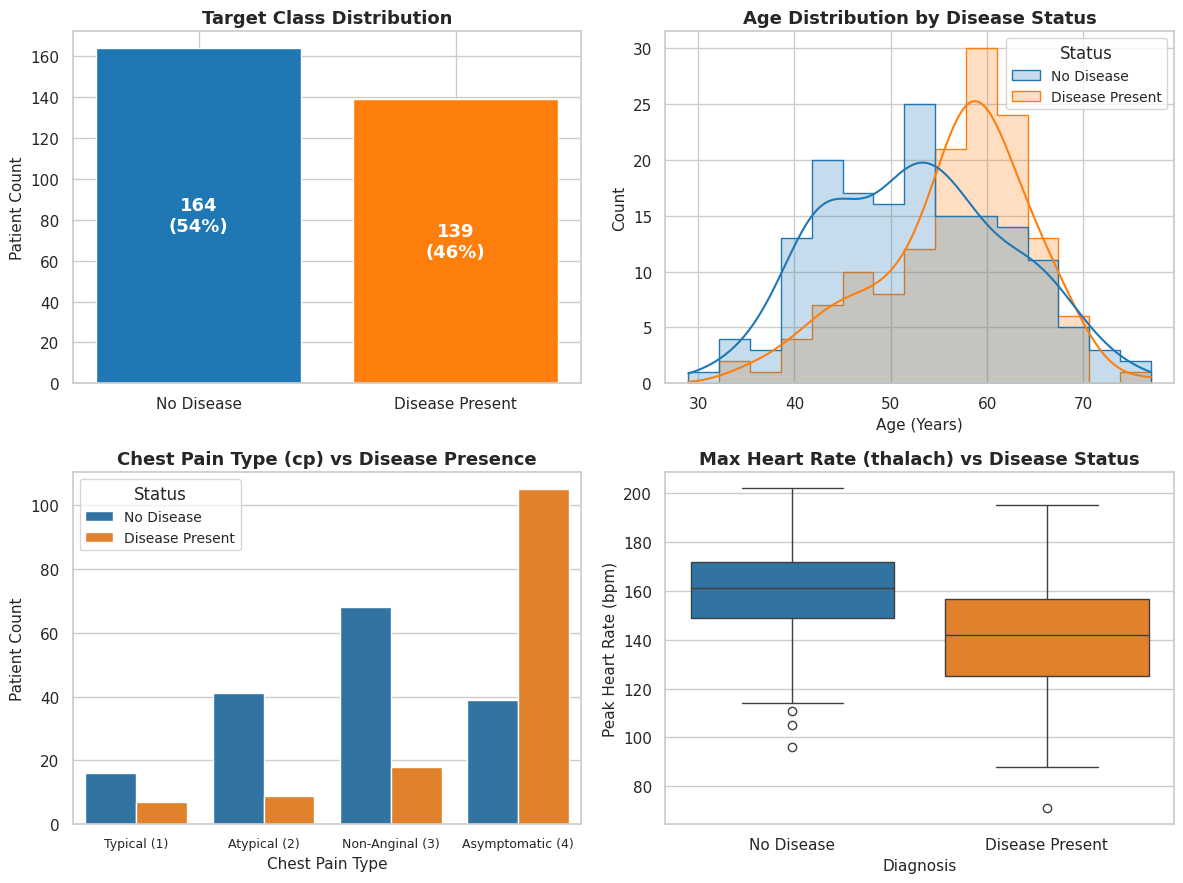

In [ ]:
# ==============================================================================
# CELL 3A: EDA - CORE DISTRIBUTIONS (2x2 grid)
# ==============================================================================
labels = {0: 'No Disease', 1: 'Disease Present'}
order = ['No Disease', 'Disease Present']
palette = {'No Disease': '#1f77b4', 'Disease Present': '#ff7f0e'}
eda = df.assign(Status=df['target'].map(labels))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Target class balance
counts = eda['Status'].value_counts()[order]
axes[0, 0].bar(order, counts.values, color=[palette[o] for o in order])
for i, v in enumerate(counts.values):
    axes[0, 0].text(i, v / 2, f"{v}\n({v / len(eda):.0%})", ha='center', va='center',
                    color='white', fontsize=13, fontweight='bold')
axes[0, 0].set_title("Target Class Distribution")
axes[0, 0].set_ylabel("Patient Count")

# 2. Age distribution by status
sns.histplot(data=eda, x='age', hue='Status', hue_order=order, palette=palette,
             kde=True, bins=15, element='step', ax=axes[0, 1])
axes[0, 1].set_title("Age Distribution by Disease Status")
axes[0, 1].set_xlabel("Age (Years)")

# 3. Chest pain type vs disease (cp is coded 1-4 in this dataset)
sns.countplot(data=eda, x='cp', hue='Status', hue_order=order, palette=palette, ax=axes[1, 0])
axes[1, 0].set_xticks(range(4))
axes[1, 0].set_xticklabels(['Typical (1)', 'Atypical (2)', 'Non-Anginal (3)',
                            'Asymptomatic (4)'], fontsize=9)
axes[1, 0].set_title("Chest Pain Type (cp) vs Disease Presence")
axes[1, 0].set_xlabel("Chest Pain Type")
axes[1, 0].set_ylabel("Patient Count")

# 4. Max heart rate vs status
sns.boxplot(data=eda, x='Status', y='thalach', order=order, hue='Status', hue_order=order,
            palette=palette, legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Max Heart Rate (thalach) vs Disease Status")
axes[1, 1].set_xlabel("Diagnosis")
axes[1, 1].set_ylabel("Peak Heart Rate (bpm)")

plt.tight_layout()
save_fig('01_eda_grid')
plt.show()

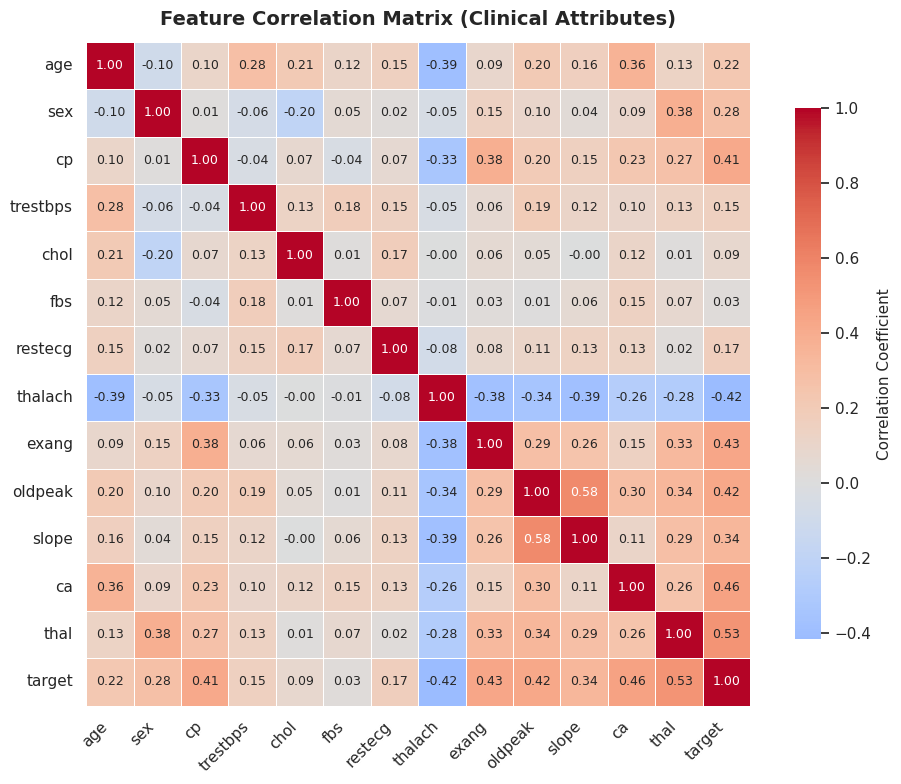

Correlation of each feature with target (sorted):
thalach    -0.42
fbs         0.03
chol        0.09
trestbps    0.15
restecg     0.17
age         0.22
sex         0.28
slope       0.34
cp          0.41
oldpeak     0.42
exang       0.43
ca          0.46
thal        0.53


In [ ]:
# ==============================================================================
# CELL 3B: CORRELATION HEATMAP + CORRELATION WITH TARGET
# ==============================================================================
corr_matrix = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=0.6, cbar_kws={'shrink': 0.8, 'label': 'Correlation Coefficient'},
            annot_kws={"size": 9})
plt.title("Feature Correlation Matrix (Clinical Attributes)", fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
save_fig('02_correlation_heatmap')
plt.show()

print("Correlation of each feature with target (sorted):")
print(corr_matrix['target'].drop('target').sort_values().round(2).to_string())

### EDA Interpretations & Clinical Observations

1. **Class balance:** 164 patients without disease (54%) and 139 with disease (46%). The classes are fairly balanced, so accuracy is a stable metric alongside precision, recall and ROC-AUC, and no resampling (SMOTE) is needed.
2. **Age:** patients with disease are older on average, with cases peaking around 58–60 years, consistent with cardiovascular risk rising with age (r = 0.22).
3. **Correlation with target:** `thal` (0.53), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42), `cp` (0.41), `slope` (0.34) and `sex` (0.28) are **positively** correlated with disease; `thalach` (max heart rate) is the only clear **negative** one (−0.42). `fbs` (0.03) and `chol` (0.09) carry almost no linear signal. Correlation describes association, not causation.
4. **Chest pain type:** `cp` is coded 1–4. Asymptomatic chest pain (type 4) has by far the highest disease prevalence, while typical, atypical and non-anginal types are mostly disease-free.
5. **Max heart rate:** patients with disease reach a **lower** median peak heart rate during the stress test than patients without disease.

## 4. Preprocessing & Feature Rationale (Practicals 5 and 6)

We keep the 13 standard clinical attributes without engineered black-box features. One pipeline, fitted on training data only:

| Group | Features | Treatment |
|---|---|---|
| Continuous with outliers | `trestbps`, `chol`, `thalach` | IQR clipping, then `StandardScaler` |
| Continuous | `age`, `oldpeak` | `StandardScaler` |
| Ordinal count | `ca` | mode imputation, then `StandardScaler` (ordered count 0–3) |
| Nominal categorical | `cp`, `restecg`, `slope`, `thal` | mode imputation, then One-Hot Encoding with `drop_first` (avoids the dummy variable trap) |
| Binary | `sex`, `fbs`, `exang` | passed through unchanged |

**Standardization vs normalization:** z-score standardization is used because logistic regression is scale-sensitive, and min-max normalization would be dominated by the remaining extreme values (e.g. `oldpeak` up to 6.2).

**Splitting & validation:** stratified 80/20 split with a fixed seed. Model selection uses **5-fold × 5-repeat stratified cross-validation on the training set**; the 61-patient test set is used once for the final report, because one patient is about 1.6% accuracy and that is too noisy for choosing models.

In [ ]:
# ==============================================================================
# CELL 4: STRATIFIED SPLIT FIRST, THEN A LEAK-FREE PREPROCESSING PIPELINE
# ==============================================================================
class IQRClipper(BaseEstimator, TransformerMixin):
    """Learns IQR limits on the data it is fitted on and clips any data to those limits."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.array(X.columns)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.lo_, self.hi_ = (q1 - 1.5 * iqr).values, (q3 + 1.5 * iqr).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, names=None):
        return self.feature_names_in_

X = df.drop(columns='target')
y = df['target']

# Split BEFORE any statistic is learned from the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

pre = ColumnTransformer([
    ('clip_scale', Pipeline([('clip', IQRClipper()), ('sc', StandardScaler())]),
        ['trestbps', 'chol', 'thalach']),
    ('num', StandardScaler(), ['age', 'oldpeak']),
    ('ca', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                     ('sc', StandardScaler())]), ['ca']),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(drop='first', handle_unknown='ignore'))]),
        ['cp', 'restecg', 'slope', 'thal']),
], remainder='passthrough')          # sex, fbs, exang stay as binary 0/1

def mk(clf):
    """Full pipeline = preprocessing + classifier (re-fitted inside every CV fold)."""
    return Pipeline([('pre', pre), ('clf', clf)])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")
print(f"Disease rate -> train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")
# Missing values are imputed with TRAIN-set modes, wherever they happen to fall after the split.
print("Missing in train:", X_train.isnull().sum()[lambda s: s > 0].to_dict(),
      "| Missing in test:", X_test.isnull().sum()[lambda s: s > 0].to_dict())

Train shape: (242, 13) | Test shape: (61, 13)
Disease rate -> train: 0.459 | test: 0.459
Missing in train: {'ca': 1, 'thal': 1} | Missing in test: {'ca': 3, 'thal': 1}


### Decision Tree Depth Justification (Pruning Analysis)
Depth is judged from **cross-validation on the training set only**; the test set is never consulted. The shaded band is ±1 standard deviation across CV folds.

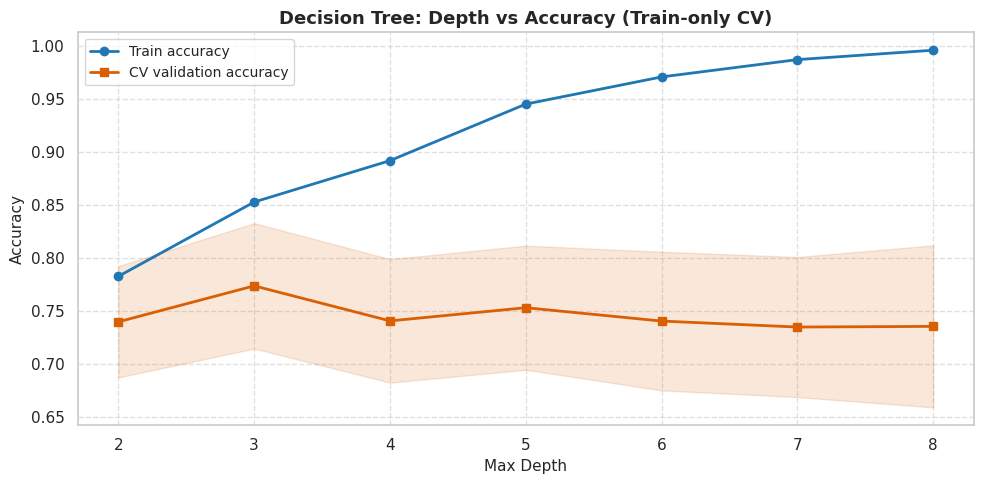

 depth  train_acc  cv_acc  cv_std
     2      0.782   0.740   0.052
     3      0.852   0.773   0.059
     4      0.892   0.740   0.058
     5      0.945   0.753   0.059
     6      0.970   0.740   0.065
     7      0.987   0.735   0.066
     8      0.996   0.735   0.076


In [ ]:
# ==============================================================================
# CELL 4B: DECISION TREE DEPTH - TRAIN vs CROSS-VALIDATION (NO TEST DATA USED)
# ==============================================================================
depths = range(2, 9)
tr, va = validation_curve(mk(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                          X_train, y_train, param_name='clf__max_depth',
                          param_range=depths, cv=cv, scoring='accuracy', n_jobs=-1)

plt.figure(figsize=(10, 5))
plt.plot(depths, tr.mean(1), 'o-', label='Train accuracy', color='#1f77b4', linewidth=2)
plt.plot(depths, va.mean(1), 's-', label='CV validation accuracy', color='#d95f02', linewidth=2)
plt.fill_between(depths, va.mean(1) - va.std(1), va.mean(1) + va.std(1),
                 color='#d95f02', alpha=0.15)
plt.title("Decision Tree: Depth vs Accuracy (Train-only CV)")
plt.xlabel("Max Depth"); plt.ylabel("Accuracy")
plt.grid(True, linestyle='--', alpha=0.6); plt.legend(); plt.tight_layout()
save_fig('03_tree_depth_curve')
plt.show()

print(pd.DataFrame({'depth': list(depths), 'train_acc': tr.mean(1).round(3),
                    'cv_acc': va.mean(1).round(3), 'cv_std': va.std(1).round(3)})
        .to_string(index=False))

**Reading the curve:** training accuracy climbs from 0.78 (depth 2) to 0.996 (depth 8) while cross-validated accuracy stays flat at 0.735–0.773 and is best at depth 3. Deeper trees therefore memorise the training data without generalising better. All differences between depths lie within one standard deviation (about ±0.06), so depth is also tuned together with `min_samples_leaf` by grid search (Section 5).

## 5. Model Benchmarking (Practicals 10, 11, 12)
Logistic Regression, Decision Tree and Gaussian Naive Bayes are compared with a `DummyClassifier` (predicts the majority class), which shows what "no skill" looks like. Logistic Regression and the Decision Tree are tuned by grid search **on the training set only**.

In [ ]:
# ==============================================================================
# CELL 5A: HYPERPARAMETER TUNING (TRAIN ONLY) + CROSS-VALIDATED COMPARISON
# ==============================================================================
lr_search = GridSearchCV(mk(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                         {'clf__C': [0.01, 0.1, 1, 10]},
                         cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)

dt_search = GridSearchCV(mk(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                         {'clf__max_depth': [2, 3, 4, 5],
                          'clf__min_samples_leaf': [5, 10, 15]},
                         cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)

print("Best Logistic Regression params:", lr_search.best_params_)
print("Best Decision Tree params      :", dt_search.best_params_)

models = {
    'Dummy (baseline)':    mk(DummyClassifier(strategy='prior')),
    'Logistic Regression': lr_search.best_estimator_,
    'Decision Tree':       dt_search.best_estimator_,
    'Gaussian NB':         mk(GaussianNB()),
}

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_rows, cv_scores, gap_rows = {}, {}, {}
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                       n_jobs=-1, return_train_score=True)
    cv_scores[name] = s
    cv_rows[name] = {k: f"{s['test_' + k].mean():.3f} (±{s['test_' + k].std():.3f})"
                     for k in scoring}
    gap_rows[name] = {'Train acc': s['train_accuracy'].mean(),
                      'CV acc': s['test_accuracy'].mean(),
                      'Gap (overfit)': s['train_accuracy'].mean() - s['test_accuracy'].mean()}

print("\n======== CROSS-VALIDATED PERFORMANCE (TRAIN SET, 5x5 REPEATED CV) ========")
print(pd.DataFrame(cv_rows).T.to_string())
print("\n============ OVERFITTING CHECK: TRAIN vs CV ACCURACY ============")
print(pd.DataFrame(gap_rows).T.round(3).to_string())

Best Logistic Regression params: {'clf__C': 1}
Best Decision Tree params      : {'clf__max_depth': 4, 'clf__min_samples_leaf': 10}

======== CROSS-VALIDATED PERFORMANCE (TRAIN SET, 5x5 REPEATED CV) ========
                           accuracy       precision          recall              f1         roc_auc
Dummy (baseline)     0.541 (±0.006)  0.000 (±0.000)  0.000 (±0.000)  0.000 (±0.000)  0.500 (±0.000)
Logistic Regression  0.824 (±0.051)  0.841 (±0.078)  0.767 (±0.074)  0.799 (±0.058)  0.901 (±0.039)
Decision Tree        0.778 (±0.058)  0.781 (±0.077)  0.723 (±0.113)  0.746 (±0.079)  0.847 (±0.051)
Gaussian NB          0.685 (±0.081)  0.624 (±0.107)  0.910 (±0.087)  0.730 (±0.054)  0.868 (±0.049)

============ OVERFITTING CHECK: TRAIN vs CV ACCURACY ============
                     Train acc  CV acc  Gap (overfit)
Dummy (baseline)         0.541   0.541         -0.000
Logistic Regression      0.868   0.824          0.044
Decision Tree            0.851   0.778          0.073
Gaussian N

In [ ]:
# ==============================================================================
# CELL 5B: FINAL EVALUATION ON THE HELD-OUT TEST SET (USED ONCE)
# ==============================================================================
test_rows, test_probs = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    mse = float(np.mean((prob - y_test.values) ** 2))       # error on predicted probabilities
    test_probs[name] = prob
    test_rows[name] = {'Accuracy': accuracy_score(y_test, pred),
                       'Precision': precision_score(y_test, pred, zero_division=0),
                       'Recall': recall_score(y_test, pred),
                       'Specificity': tn / (tn + fp),
                       'F1': f1_score(y_test, pred),
                       'ROC-AUC': roc_auc_score(y_test, prob),
                       'MSE': mse, 'RMSE': np.sqrt(mse),
                       'FN': fn, 'FP': fp}

tab = pd.DataFrame(test_rows).T.astype({'FN': int, 'FP': int})
print("================== TEST-SET PERFORMANCE (n = %d) ==================" % len(y_test))
print(tab.round(3).to_string())
print("MSE / RMSE: predicted probability vs actual label (lower is better).")
print("With %d test patients one patient moves accuracy by ~%.1f%%; rely on CV for comparisons."
      % (len(y_test), 100 / len(y_test)))

================== TEST-SET PERFORMANCE (n = 61) ==================
                     Accuracy  Precision  Recall  Specificity     F1  ROC-AUC    MSE   RMSE  FN  FP
Dummy (baseline)        0.541      0.000   0.000        1.000  0.000    0.500  0.248  0.498  28   0
Logistic Regression     0.852      0.806   0.893        0.818  0.847    0.957  0.086  0.293   3   6
Decision Tree           0.803      0.833   0.714        0.879  0.769    0.867  0.150  0.387   8   4
Gaussian NB             0.607      0.543   0.893        0.364  0.676    0.847  0.353  0.594   3  21
MSE / RMSE: predicted probability vs actual label (lower is better).
With 61 test patients one patient moves accuracy by ~1.6%; rely on CV for comparisons.


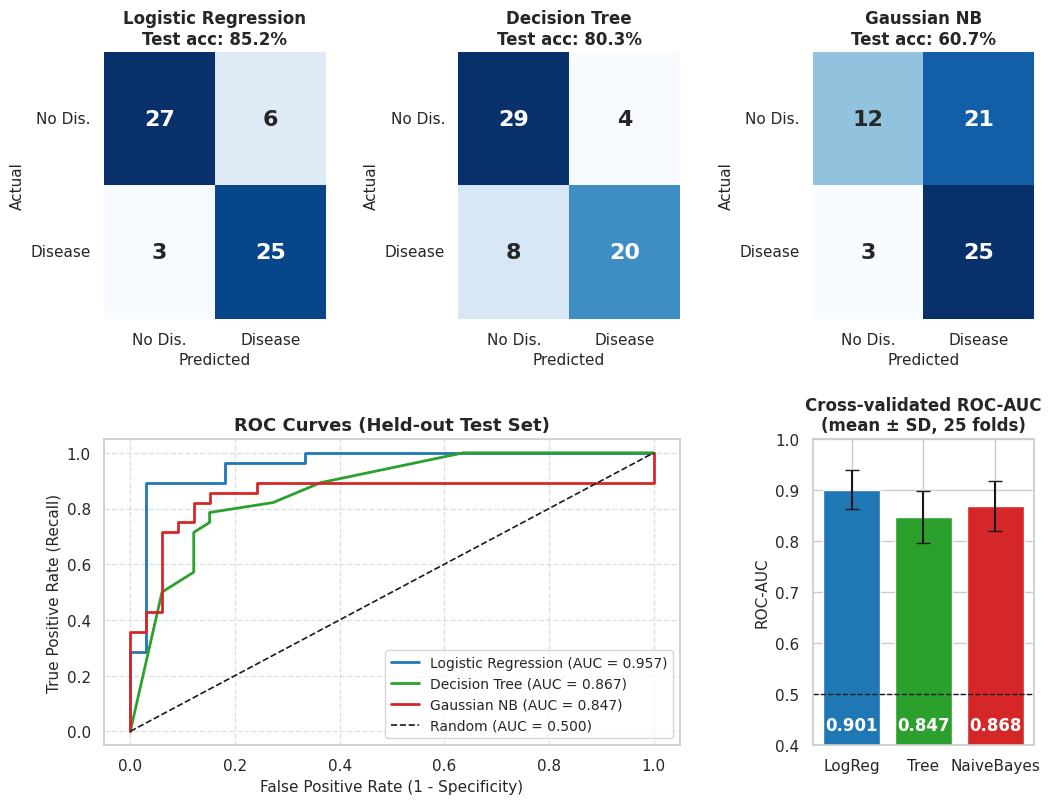

In [ ]:
# ==============================================================================
# CELL 5C: MODEL EVALUATION FIGURE (CONFUSION MATRICES, ROC, CV ROC-AUC)
# ==============================================================================
shown = {k: v for k, v in models.items() if k != 'Dummy (baseline)'}
colors = {'Logistic Regression': '#1f77b4', 'Decision Tree': '#2ca02c', 'Gaussian NB': '#d62728'}
short = {'Logistic Regression': 'LogReg', 'Decision Tree': 'Tree', 'Gaussian NB': 'NaiveBayes'}

fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15], hspace=0.42, wspace=0.6)

# Row 1: confusion matrices (test set)
for i, (name, model) in enumerate(shown.items()):
    ax = fig.add_subplot(gs[0, i])
    pred = model.predict(X_test)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                ax=ax, annot_kws={"size": 16, "weight": "bold"},
                xticklabels=['No Dis.', 'Disease'], yticklabels=['No Dis.', 'Disease'])
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_title(f"{name}\nTest acc: {accuracy_score(y_test, pred):.1%}", fontsize=12)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

# Row 2 left: ROC curves (test set)
ax = fig.add_subplot(gs[1, :2])
for name in shown:
    fpr, tpr, _ = roc_curve(y_test, test_probs[name])
    ax.plot(fpr, tpr, linewidth=2, color=colors[name],
            label=f"{name} (AUC = {roc_auc_score(y_test, test_probs[name]):.3f})")
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.2, label="Random (AUC = 0.500)")
ax.set_title("ROC Curves (Held-out Test Set)")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right"); ax.grid(True, linestyle='--', alpha=0.6)

# Row 2 right: cross-validated ROC-AUC with error bars (more reliable than 61 test patients)
ax = fig.add_subplot(gs[1, 2])
means = [cv_scores[n]['test_roc_auc'].mean() for n in shown]
stds = [cv_scores[n]['test_roc_auc'].std() for n in shown]
ax.bar([short[n] for n in shown], means, yerr=stds, capsize=5,
       color=[colors[n] for n in shown])
for i, m in enumerate(means):
    ax.text(i, 0.43, f"{m:.3f}", ha='center', color='white', fontweight='bold')
ax.axhline(0.5, color='k', linestyle='--', linewidth=1)
ax.set_ylim(0.4, 1.0)
ax.set_title("Cross-validated ROC-AUC\n(mean ± SD, 25 folds)", fontsize=12)
ax.set_ylabel("ROC-AUC")

save_fig('04_model_evaluation')
plt.show()

### Metric Discussion for Medical Diagnostics
A **False Negative** (an ill patient classified as healthy) is the costly error because it delays treatment, while a **False Positive** leads to follow-up testing, which is manageable. **Recall (sensitivity)** is therefore prioritised over raw accuracy, but always read together with **specificity and precision** (a model that flags everyone has perfect recall and is useless) and with **ROC-AUC**, which is threshold-independent. **MSE / RMSE** (Practicals 11 and 12) are computed on the predicted probabilities. The Dummy baseline and the cross-validated standard deviations show which differences are real and which are noise on 303 patients.

## 6. Interpretability, Decision Threshold and Fairness

Display-tree test accuracy: 0.803 | benchmark-tree test accuracy: 0.803


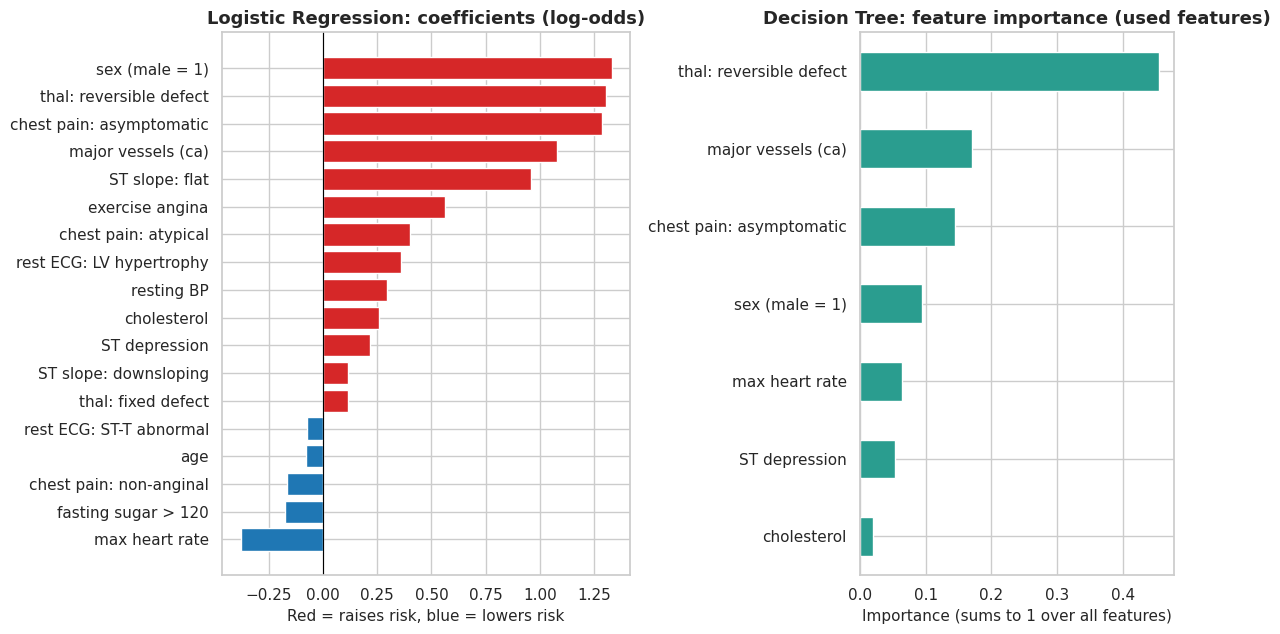

Reference categories: chest pain = typical, rest ECG = normal, ST slope = upsloping, thal = normal.
Continuous features are standardised, so their coefficients are per +1 SD.

--- Strongest risk-increasing terms ---
                 Feature  Coefficient  Odds Ratio
          sex (male = 1)        1.330       3.782
 thal: reversible defect        1.304       3.685
chest pain: asymptomatic        1.285       3.613
      major vessels (ca)        1.077       2.935
          ST slope: flat        0.959       2.609

--- Strongest risk-decreasing terms ---
                Feature  Coefficient  Odds Ratio
         max heart rate       -0.379       0.685
    fasting sugar > 120       -0.173       0.841
chest pain: non-anginal       -0.163       0.850
                    age       -0.076       0.927
rest ECG: ST-T abnormal       -0.071       0.931


In [ ]:
# ==============================================================================
# CELL 6A: LOGISTIC REGRESSION COEFFICIENTS vs DECISION TREE FEATURE IMPORTANCE
# ==============================================================================
PRETTY = {'age': 'age', 'sex': 'sex (male = 1)', 'trestbps': 'resting BP',
          'chol': 'cholesterol', 'fbs': 'fasting sugar > 120', 'thalach': 'max heart rate',
          'exang': 'exercise angina', 'oldpeak': 'ST depression', 'ca': 'major vessels (ca)',
          'cp_2.0': 'chest pain: atypical', 'cp_3.0': 'chest pain: non-anginal',
          'cp_4.0': 'chest pain: asymptomatic', 'restecg_1.0': 'rest ECG: ST-T abnormal',
          'restecg_2.0': 'rest ECG: LV hypertrophy', 'slope_2.0': 'ST slope: flat',
          'slope_3.0': 'ST slope: downsloping', 'thal_6.0': 'thal: fixed defect',
          'thal_7.0': 'thal: reversible defect'}
pretty = lambda n: PRETTY.get(n, n)

# --- Logistic Regression: coefficients of the tuned, fitted pipeline
lr_pipe = models['Logistic Regression']
lr_names = [pretty(n.split('__')[-1]) for n in lr_pipe.named_steps['pre'].get_feature_names_out()]
coefs = lr_pipe.named_steps['clf'].coef_[0]
fi = (pd.DataFrame({'Feature': lr_names, 'Coefficient': coefs, 'Odds Ratio': np.exp(coefs)})
        .sort_values('Coefficient', ascending=False).reset_index(drop=True))

# --- Decision Tree for DISPLAY: same tuned hyper-parameters, fitted on UNSCALED features so the
#     split thresholds are in real clinical units. Trees do not depend on feature scaling, so the
#     structure matches the benchmarked tree; the benchmark results above are NOT affected.
pre_tree = ColumnTransformer([
    ('ca', SimpleImputer(strategy='most_frequent'), ['ca']),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(drop='first', handle_unknown='ignore'))]),
        ['cp', 'restecg', 'slope', 'thal']),
], remainder='passthrough')
best = {k.replace('clf__', ''): v for k, v in dt_search.best_params_.items()}
tree_disp = Pipeline([('pre', pre_tree),
                      ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE, **best))
                      ]).fit(X_train, y_train)
tree_clf = tree_disp.named_steps['clf']
tree_names = [pretty(n.split('__')[-1]) for n in pre_tree.get_feature_names_out()]
imp = pd.Series(tree_clf.feature_importances_, index=tree_names).sort_values(ascending=False)

print("Display-tree test accuracy: %.3f | benchmark-tree test accuracy: %.3f"
      % (accuracy_score(y_test, tree_disp.predict(X_test)),
         accuracy_score(y_test, models['Decision Tree'].predict(X_test))))

fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 6.5), gridspec_kw={'width_ratios': [1.3, 1]})
srt = fi.sort_values('Coefficient')
axL.barh(srt['Feature'], srt['Coefficient'],
         color=['#d62728' if c > 0 else '#1f77b4' for c in srt['Coefficient']])
axL.axvline(0, color='black', linewidth=0.8)
axL.set_title("Logistic Regression: coefficients (log-odds)")
axL.set_xlabel("Red = raises risk, blue = lowers risk")
imp[imp > 0].head(8).sort_values().plot.barh(ax=axR, color='#2a9d8f')   # skip unused features
axR.set_title("Decision Tree: feature importance (used features)")
axR.set_xlabel("Importance (sums to 1 over all features)")
plt.tight_layout()
save_fig('05_interpretability')
plt.show()

print("Reference categories: chest pain = typical, rest ECG = normal, ST slope = upsloping, "
      "thal = normal.")
print("Continuous features are standardised, so their coefficients are per +1 SD.")
print("\n--- Strongest risk-increasing terms ---")
print(fi.head(5).round(3).to_string(index=False))
print("\n--- Strongest risk-decreasing terms ---")
print(fi.tail(5).iloc[::-1].round(3).to_string(index=False))

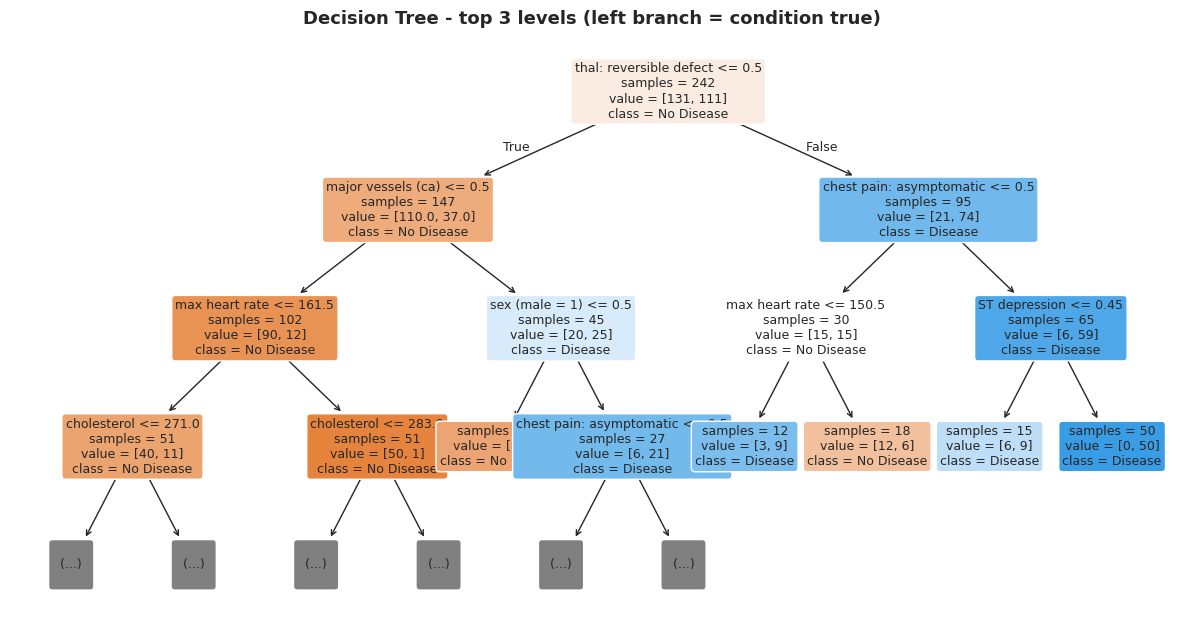

Full rule set (all levels):
|--- thal: reversible defect <= 0.50
|   |--- major vessels (ca) <= 0.50
|   |   |--- max heart rate <= 161.50
|   |   |   |--- cholesterol <= 271.00
|   |   |   |   |--- class: 0
|   |   |   |--- cholesterol >  271.00
|   |   |   |   |--- class: 0
|   |   |--- max heart rate >  161.50
|   |   |   |--- cholesterol <= 283.00
|   |   |   |   |--- class: 0
|   |   |   |--- cholesterol >  283.00
|   |   |   |   |--- class: 0
|   |--- major vessels (ca) >  0.50
|   |   |--- sex (male = 1) <= 0.50
|   |   |   |--- class: 0
|   |   |--- sex (male = 1) >  0.50
|   |   |   |--- chest pain: asymptomatic <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- chest pain: asymptomatic >  0.50
|   |   |   |   |--- class: 1
|--- thal: reversible defect >  0.50
|   |--- chest pain: asymptomatic <= 0.50
|   |   |--- max heart rate <= 150.50
|   |   |   |--- class: 1
|   |   |--- max heart rate >  150.50
|   |   |   |--- class: 0
|   |--- chest pain: asymptomatic >  0.50
|   

In [ ]:
# ==============================================================================
# CELL 6B: DECISION TREE RULES (REAL CLINICAL UNITS)
# ==============================================================================
plt.figure(figsize=(12, 6.5))
plot_tree(tree_clf, feature_names=tree_names, class_names=['No Disease', 'Disease'],
          filled=True, rounded=True, fontsize=9, impurity=False, max_depth=3)
plt.title("Decision Tree - top 3 levels (left branch = condition true)")
plt.tight_layout()
save_fig('06_decision_tree')
plt.show()

print("Full rule set (all levels):")
print(export_text(tree_clf, feature_names=tree_names))

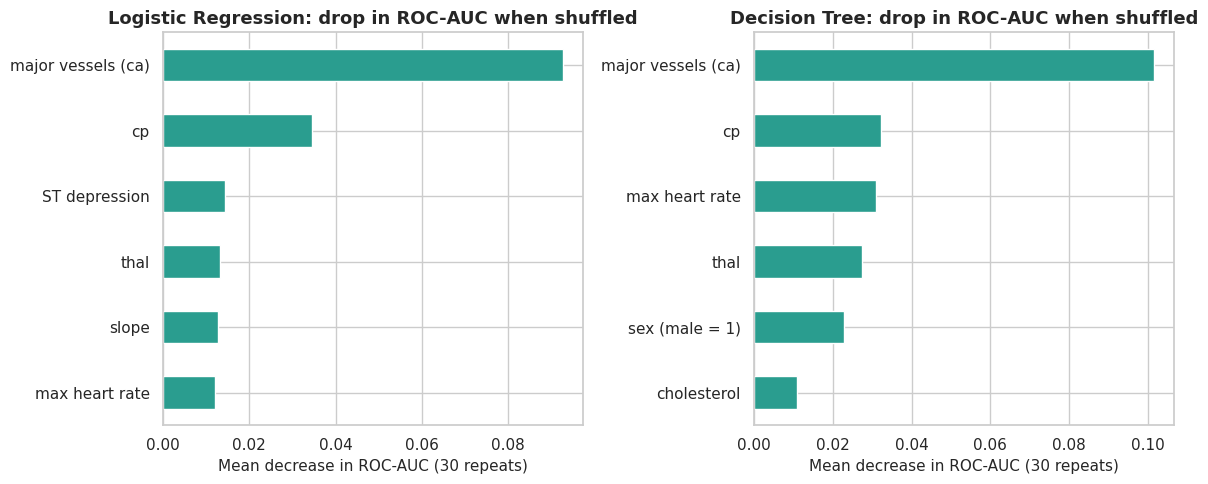

In [ ]:
# ==============================================================================
# CELL 6C: PERMUTATION IMPORTANCE ON THE TEST SET (MODEL-AGNOSTIC, ORIGINAL FEATURES)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['Logistic Regression', 'Decision Tree']):
    r = permutation_importance(models[name], X_test, y_test, scoring='roc_auc',
                               n_repeats=30, random_state=RANDOM_STATE)
    sp = pd.Series(r.importances_mean, index=[pretty(c) for c in X_test.columns]).sort_values()
    sp.tail(6).plot.barh(ax=ax, color='#2a9d8f')
    ax.set_title(f"{name}: drop in ROC-AUC when shuffled")
    ax.set_xlabel("Mean decrease in ROC-AUC (30 repeats)")
plt.tight_layout()
save_fig('07_permutation_importance')
plt.show()

### Recall-oriented decision threshold
Because false negatives are the costly error, the Logistic Regression threshold is lowered until out-of-fold **training** predictions reach about 90% recall. The threshold is never tuned on the test set.

In [ ]:
# ==============================================================================
# CELL 7: RECALL-ORIENTED DECISION THRESHOLD, CHOSEN ON TRAIN DATA ONLY
# ==============================================================================
TARGET_RECALL = 0.90
oof_prob = cross_val_predict(lr_pipe, X_train, y_train,
                             cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                             method='predict_proba')[:, 1]   # out-of-fold probabilities

prec, rec, thr = precision_recall_curve(y_train, oof_prob)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
threshold = thr[ok[-1]] if len(ok) else 0.5   # highest threshold that still meets the target
print(f"Threshold chosen on training data (out-of-fold): {threshold:.3f}")

prob_test = lr_pipe.predict_proba(X_test)[:, 1]
for label, t in [("Default 0.5", 0.5), (f"Recall-oriented {threshold:.2f}", threshold)]:
    pred = (prob_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{label:>24}: recall={tp/(tp+fn):.3f}  specificity={tn/(tn+fp):.3f}  "
          f"precision={tp/(tp+fp):.3f}  FN={fn}  FP={fp}")

Threshold chosen on training data (out-of-fold): 0.293
             Default 0.5: recall=0.893  specificity=0.818  precision=0.806  FN=3  FP=6
    Recall-oriented 0.29: recall=0.964  specificity=0.697  precision=0.730  FN=1  FP=10


### Fairness check by sex
The dataset is about 68% male, so performance is compared for male and female patients using out-of-fold predictions on the training set (the test set is not reused).

In [ ]:
# ==============================================================================
# CELL 6D: FAIRNESS CHECK BY SEX (OUT-OF-FOLD PREDICTIONS ON THE TRAINING SET)
# ==============================================================================
oof = cross_val_predict(lr_pipe, X_train, y_train,
                        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                        method='predict_proba')[:, 1]
oof_pred = (oof >= 0.5).astype(int)

rows = {}
for g, lab in [(1, 'Male'), (0, 'Female')]:
    m = (X_train['sex'] == g).values
    yt, yp = y_train.values[m], oof_pred[m]
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    rows[lab] = {'n': int(m.sum()), 'Disease rate': yt.mean(), 'Accuracy': (tp + tn) / m.sum(),
                 'Recall': tp / (tp + fn), 'Specificity': tn / (tn + fp),
                 'ROC-AUC': roc_auc_score(yt, oof[m]), 'FN': int(fn), 'FP': int(fp)}
print("Logistic Regression, out-of-fold predictions on the training set (threshold 0.5):")
print(pd.DataFrame(rows).T.round(3).to_string())
print("Small subgroups: read differences as indicative, not conclusive.")

Logistic Regression, out-of-fold predictions on the training set (threshold 0.5):
            n  Disease rate  Accuracy  Recall  Specificity  ROC-AUC    FN    FP
Male    165.0         0.564     0.806   0.796        0.819    0.888  19.0  13.0
Female   77.0         0.234     0.909   0.667        0.983    0.911   6.0   1.0
Small subgroups: read differences as indicative, not conclusive.


## 7. Results Discussion

**Best model: Logistic Regression.** In 5×5 repeated cross-validation on the training set it reached ROC-AUC 0.901 (±0.039), accuracy 0.824 (±0.051) and recall 0.767 (±0.074), against 0.500 AUC and 0.541 accuracy for the Dummy baseline. On the held-out test set (n = 61) it scored accuracy 0.852, recall 0.893, specificity 0.818 and ROC-AUC 0.957 (3 false negatives, 6 false positives).

**Cross-validation is the main evidence.** The test AUC (0.957) is higher than the CV AUC (0.901) because 61 patients is a small sample (one patient ≈ 1.6% accuracy), so the CV figures are the more reliable estimate of future performance.

**Model comparison.**
- *Logistic Regression vs Decision Tree:* CV AUC 0.901 vs 0.847. The gap (0.054) is about one fold standard deviation, so Logistic Regression is better, but not decisively.
- *Decision Tree:* less stable (recall SD ±0.113) and misses more patients on the test set (8 false negatives vs 3), though it raises fewer false alarms (4 false positives vs 6).
- *Gaussian Naive Bayes:* highest CV recall (0.910) but the lowest accuracy (0.685 CV, 0.607 test) and specificity (0.364); it flags 21 of 33 healthy test patients. Its Gaussian and conditional-independence assumptions fit poorly with binary one-hot features and correlated clinical variables, so its high recall is not clinically useful.

**Overfitting check.** Unconstrained trees reach 0.996 train accuracy at depth 8 while CV accuracy stays at 0.735–0.773 (Section 4). The tuned tree (grid search on training CV: `max_depth` = 4, `min_samples_leaf` = 10) limits this with a minimum leaf size; the train-vs-CV table in Cell 5A reports each model's gap.

**Key predictors.** Logistic Regression and the tree agree. Reversible-defect thalassemia (`thal` = 7; odds ratio 3.69), asymptomatic chest pain (`cp` = 4; OR 3.61), number of major vessels `ca` (OR 2.94 per +1 SD) and a flat ST slope (OR 2.61) raise risk, while a higher maximum heart rate lowers it (OR 0.69 per +1 SD). The tree splits first on `thal` = 7 (importance 0.455), then `ca` (0.170) and `cp` = 4 (0.099). The large `sex` coefficient (male, OR 3.78) is an association in a male-dominated sample, not a biological claim.

**Recall trade-off.** Lowering the threshold from 0.50 to 0.29 (chosen on out-of-fold training predictions, not on test data) raised test recall from 0.893 to 0.964 (false negatives 3 → 1) at the cost of specificity (0.818 → 0.697) and 4 more false positives (6 → 10). Whether this trade is worthwhile is a clinical decision.

**Fairness.** Cell 6D compares male and female patients. About a third of the patients are female, so subgroup differences are indicative only.

## 8. Limitations, Ethical Considerations & Course Outcomes

**Limitations & dataset bias**
1. **Sample size and single-site data:** 303 patients from the Cleveland Clinic Foundation (collected in the 1980s), about 68% male, so results may not generalise to women, other populations or modern practice. The test set has only 61 patients, so its estimates are noisy.
2. **Label definition:** `target` is a binarised angiographic severity grade (0 vs 1–4), a proxy for "heart disease", not a full clinical diagnosis.
3. **No external validation:** all evaluation is internal. Hyperparameters were tuned with the same CV used for reporting, so CV scores may be slightly optimistic.
4. **Missing data:** only 6 values (`ca`, `thal`) were imputed, so the impact is small, but mode imputation ignores relationships between features.
5. **Association, not causation:** coefficients and importances describe patterns in this dataset; `sex` in particular reflects sampling imbalance.

**Ethical considerations**
- The model is an educational prototype, **not a diagnostic tool**. Real use would need clinical validation, calibration checks, fairness audits across sex and age, and clinician oversight.
- A false negative can delay treatment, which is why recall, the decision threshold and subgroup performance are discussed explicitly.
- The dataset is public and anonymised; no personal data was collected for this project.

**Course outcome mapping (01CE0517)**

| CO | Course outcome | Where demonstrated |
|---|---|---|
| CO1 | Data-science concepts, tools and workflow | Section 1: problem framing and end-to-end leak-free pipeline in Python |
| CO2 | Data acquisition, cleaning, preprocessing | Sections 2 and 4 (Practicals 4, 5, 6): `'?'` handling, mode imputation, IQR capping, one-hot encoding, standardization |
| CO3 | EDA and statistical measures | Section 3 (Practicals 3, 8): descriptive statistics, distributions, correlations |
| CO4 | ML algorithms and evaluation metrics | Section 5 (Practicals 10, 11, 12): Logistic Regression, Decision Tree, Naive Bayes; accuracy, precision, recall, F1, ROC-AUC, MSE/RMSE, cross-validation |
| CO5 | Ethics, fairness and bias | Sections 6 and 8: sex-subgroup check, dataset bias, limitations, disclaimer |

In [ ]:
# ==============================================================================
# CELL 8: BUNDLE ALL FIGURES FOR THE PRESENTATION SLIDES
# ==============================================================================
import shutil
print(sorted(os.listdir(FIG_DIR)))
shutil.make_archive('figures', 'zip', FIG_DIR)
try:
    from google.colab import files
    files.download('figures.zip')            # downloads all 200-dpi PNGs in one zip
except ImportError:
    print("Saved as figures.zip")

['01_eda_grid.png', '02_correlation_heatmap.png', '03_tree_depth_curve.png', '04_model_evaluation.png', '05_interpretability.png', '06_decision_tree.png', '07_permutation_importance.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>